In [6]:
!uv add PyTDC rdkit torch transformers lightgbm scikit-learn

Resolved 152 packages in 3ms
Checked 126 packages in 26ms


In [4]:
uv pip install "setuptools<82"


.venv/bin/python: No module named uv
Note: you may need to restart the kernel to use updated packages.


In [8]:
import numpy as np, pandas as pd
from tdc.multi_pred import DTI

data = DTI(name='KIBA')
df = data.get_data()

print(df.shape)
print(df.columns.tolist())   # Drug_ID, Drug, Target_ID, Target, Y
print(f"drugs:   {df.Drug_ID.nunique()}")
print(f"targets: {df.Target_ID.nunique()}")
df.head(3)

Downloading...
100%|██████████| 96.6M/96.6M [00:07<00:00, 13.4MiB/s]
Loading...
Done!


(117657, 5)
['Drug_ID', 'Drug', 'Target_ID', 'Target', 'Y']
drugs:   2068
targets: 229


,Drug_ID,Drug,Target_ID,Target,Y
0,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,O00141,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1
1,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,O14920,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1
2,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,O15111,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1


The scale is in original affinity scale, so we will take the minimum!
The original data has been updated!


count    117657.000000
mean         11.720685
std           0.834272
min           0.000000
25%          11.200000
50%          11.520216
75%          11.923909
max          17.200179
Name: Y, dtype: float64


<Axes: >

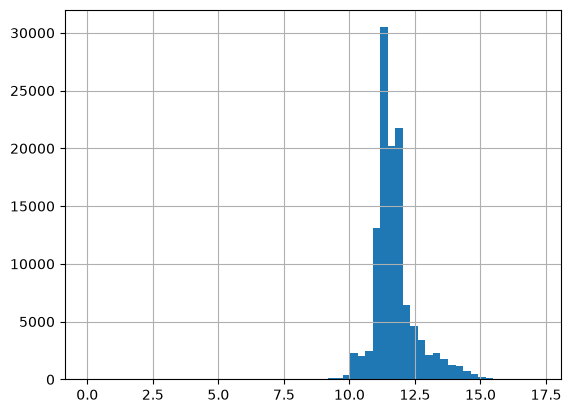

In [9]:
data.harmonize_affinities(mode='max_affinity')  # collapse duplicate pairs
df = data.get_data()

print(df.Y.describe())
df.Y.hist(bins=60)

In [25]:
from rdkit.ML.Cluster import Butina

SIM_CUTOFF = 0.5          # no test molecule within this of any train molecule
all_smi = sorted(set(df.Drug))
fps = [fp(s) for s in all_smi]
keep = [i for i, f in enumerate(fps) if f is not None]
all_smi, fps = [all_smi[i] for i in keep], [fps[i] for i in keep]
n = len(fps)

# condensed distance matrix
dists = []
for i in range(1, n):
    dists.extend(1 - s for s in DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i]))

clusters = Butina.ClusterData(dists, n, 1 - SIM_CUTOFF, isDistData=True)
clusters = sorted(clusters, key=len)      # small/singleton clusters first

# fill test from the most isolated clusters
test_idx, target_n = set(), int(0.2 * n)
for c in clusters:
    if len(test_idx) >= target_n: break
    test_idx.update(c)
train_idx = set(range(n)) - test_idx

# enforce the bound — Butina is a leader algorithm, it doesn't guarantee it
train_fps = [fps[i] for i in train_idx]
final_test = [i for i in test_idx
              if max(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)) < SIM_CUTOFF]

print(f"test drugs: {len(test_idx)} → {len(final_test)} after pruning")

test_smi  = {all_smi[i] for i in final_test}
train_smi = {all_smi[i] for i in train_idx}

test drugs: 413 → 350 after pruning


In [ ]:
train_smi

{'COc1ccc(Nc2nccc(Nc3c(NC(C)C(C)(C)C)c(=O)c3=O)n2)cc1OC',
 'Cc1c(NC(=O)c2ccc(C(C)(C)C)cc2)cccc1-c1cc(Nc2ccc(C(=O)N3CCOCC3)cn2)c(=O)n(C)c1',
 'Cn1nc(-c2ccc3cc[nH]c3c2)c2c(N)ncnc21',
 'N#Cc1ccc(NC(=O)Nc2ccnc3cc(C(F)(F)F)ccc23)nc1',
 'O=C1c2c(c3c4ccc(O)cc4n(C4OC(C(O)CO)C(O)C4O)c3c3[nH]c4cc(O)ccc4c23)C(=O)N1NC(CO)CO',
 'CCCCCCCCCCCCCCCCSCC(C[N+](C)(C)C)OC.[Br-]',
 'O=C(NC(CO)Cc1ccccc1)c1ccc(-c2ccncc2)cc1',
 'CC(NC(=O)C(C)NS(=O)(=O)c1cccc2cnccc12)C(=O)NC(C)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)O',
 'NC(=O)c1cccc2[nH]c(-c3cccc(NCCN4CCCC4)n3)nc12',
 'O=C1C=CC(=c2ccc(=C3NNC4=C3Cc3cc(C(=O)NCc5ccncc5)ccc34)cc2)C=C1',
 'COc1ccc(CNc2c(Nc3ccc4[nH]ncc4c3)c(=O)c2=O)cc1',
 'CC(C)(CO)CNc1nccc(-c2c(-c3ccc(F)cc3)nc3c(OCC(F)(F)F)nccn23)n1',
 'COc1ccc(Nc2cc3c(cc2Nc2ccc(OC)cc2)C(=O)NC3=O)cc1',
 'Cc1cc(Cl)ccc1NC(=S)NNC(=O)C(O)(c1ccccc1)c1ccccc1',
 'COC1C(N(C)C(=O)CNC(=O)OC(C)(C)C)CC2OC1(C)n1c3ccccc3c3c4c(c5c6ccccc6n2c5c31)C(=O)NC4',
 'CCCNC(=O)c1ccc(Nc2nc(NCC(F)(F)F

count    350.000000
mean       0.335231
std        0.074719
min        0.163265
25%        0.277276
50%        0.327188
75%        0.384615
max        0.490566
dtype: float64


<Axes: >

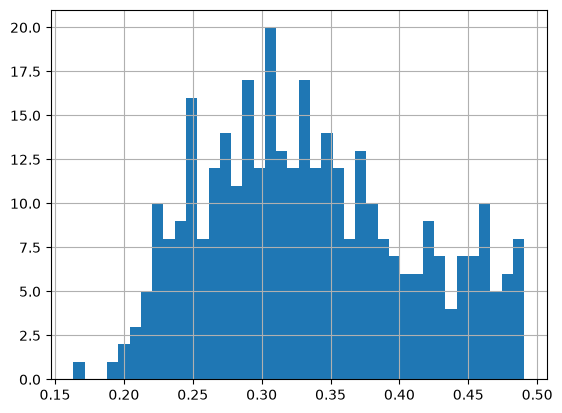

In [26]:
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def fp(smiles):
    m = Chem.MolFromSmiles(smiles)
    return gen.GetFingerprint(m) if m else None

# train_smi = sorted(set(train.Drug))
# test_smi  = sorted(set(test.Drug))
train_fps = [f for f in map(fp, train_smi) if f is not None]

novelty = {}
for s in test_smi:
    f = fp(s)
    if f is None: continue
    novelty[s] = max(DataStructs.BulkTanimotoSimilarity(f, train_fps))

nov = pd.Series(novelty)
print(nov.describe())
nov.hist(bins=40)

In [29]:
rng = np.random.default_rng(42)

# carve a validation set out of the train molecules (drug-disjoint, for early stopping)
pool = np.array(sorted(train_smiles))
pool = pool[rng.permutation(len(pool))]
n_val = int(0.125 * len(pool))

valid_smiles = set(pool[:n_val])
train_smiles = set(pool[n_val:])

train_df = df[df.Drug.isin(train_smiles)].copy()
valid_df = df[df.Drug.isin(valid_smiles)].copy()
test_df  = df[df.Drug.isin(test_smiles)].copy()

# no molecule appears in two splits
assert not (train_smiles & valid_smiles)
assert not (train_smiles & test_smiles)
assert not (valid_smiles & test_smiles)

for name, d in [('train', train_df), ('valid', valid_df), ('test', test_df)]:
    print(f"{name:5} {len(d):>7} pairs  {d.Drug_ID.nunique():>5} drugs")

train   81869 pairs   1449 drugs
valid   10805 pairs    206 drugs
test    21375 pairs    350 drugs


In [31]:
# fingerprint every molecule once, as a numpy row
drug_fp = {}
for s in set(df.Drug):
    f = fp(s)
    if f is not None:
        a = np.zeros(2048, dtype=np.uint8)
        DataStructs.ConvertToNumpyArray(f, a)
        drug_fp[s] = a
print(f"{len(drug_fp)} molecules fingerprinted")


def build(d):
    """DataFrame -> (features, labels, filtered frame).

    Drops rows whose molecule failed to parse or whose target has no
    ESM embedding, so X, y and the frame stay row-aligned.
    """
    d = d[d.Drug.isin(drug_fp) & d.Target_ID.isin(target_emb)].copy()
    X = np.hstack([
        np.stack([drug_fp[s] for s in d.Drug]).astype(np.float32),   # 2048 bits
        np.stack([target_emb[t] for t in d.Target_ID]),              # 1280 ESM dims
    ])
    return X, d.Y.values.astype(np.float32), d

2068 molecules fingerprinted


In [32]:
Xtr, ytr, train_df = build(train_df)
Xva, yva, valid_df = build(valid_df)
Xte, yte, test_df  = build(test_df)
print(Xtr.shape, Xva.shape, Xte.shape)

NameError: name 'target_emb' is not defined

In [28]:
print(f"test drugs  {train_smi.Drug_ID.nunique()}")
print(f"test pairs  {len(test_df)}")
print(f"targets hit {test_df.Target_ID.nunique()} / 229")

# the one that matters
binders = test_df[test_df.Y >= 12.1]
print(f"\nbinder pairs      {len(binders)} ({len(binders)/len(test_df):.1%})")
print(f"drugs ≥1 binder   {binders.Drug_ID.nunique()} / {test_df.Drug_ID.nunique()}")

# compare against train — is the test set abnormally floor-heavy?
print(f"\ntrain binder rate {(train_df.Y >= 12.1).mean():.1%}")
print(f"test  binder rate {(test_df.Y  >= 12.1).mean():.1%}")

AttributeError: 'set' object has no attribute 'Drug_ID'